# Exponentials & natural logs

**Same x in each row.** `e ≈ 2.7`; values are rounded.

| x | exp(x) = eˣ | ln(x) |
|---:|---:|---:|
| -10 | tiny, but positive | — |
| -3 | 0.05 | — |
| -1 | 0.4 | — |
| -0.1 | 0.9 | — |
| **0** | **1** | — |
| 0.001 | just above 1 | -6.9 |
| 0.01 | just above 1 | -4.6 |
| 0.1 | 1.1 | -2.3 |
| 0.25 | 1.3 | -1.4 |
| 0.5 | 1.6 | -0.7 |
| 0.75 | 2.1 | -0.3 |
| 0.9 | 2.5 | -0.1 |
| **1** | **2.7** | **0** |
| 2 | 7.4 | +0.7 |
| e ≈ 2.7 | 15.2 | +1 |
| e² ≈ 7.4 | 1618.2 | +2 |

- **exp:** negative x → between 0 and 1; x = 0 → 1; positive x → above 1. **Always positive.**
- **ln:** undefined at 0 or below (—). Between 0 and 1 → negative; at 1 → 0; above 1 → positive.

**exp and ln undo each other:** `exp(1) ≈ 2.7` → `ln(2.7) ≈ 1`.

**Log-probabilities:** smaller positive probability → more negative log; `ln(1) = 0`.


## Odds, log-odds & sigmoid

**Read left → right.** Sigmoid returns the starting probability. Values are rounded.

| Probability p | Odds p/(1−p) | Log-odds z = ln(odds) | Sigmoid(z) → p |
|---:|---:|---:|---:|
| 10% | 1/9 | -2.2 | 10% |
| 25% | 1/3 | -1.1 | 25% |
| **50%** | **1** | **0** | **50%** |
| 75% | 3 | +1.1 | 75% |
| 90% | 9 | +2.2 | 90% |

- **Odds:** probability of yes ÷ probability of no; `75% / 25% = 3`.
- **Log-odds:** negative → below 50%; zero → 50%; positive → above 50%.
- **Sigmoid:** `1 / (1 + exp(-z))` converts log-odds back to a probability between 0 and 1.
- **Different zeros:** log-probability `ln(p)` is 0 at **100%**; log-odds is 0 at **50%**.

Based on [Daniel Voigt Godoy’s Chapter 3](https://github.com/dvgodoy/PyTorchStepByStep/blob/master/Chapter03.ipynb).


## DPO: winner minus loser

**Ratio = model probability ÷ reference probability.** Here β = 1; values rounded.

`z = β × [ln(winner ratio) − ln(loser ratio)]`

$$\operatorname{sigmoid}(z) = \frac{1}{1 + e^{-z}}$$

| Winner ratio → ln | Loser ratio → ln | Gap z | Sigmoid(z) | ln(sigmoid) | Loss = −ln(sigmoid) |
|---:|---:|---:|---:|---:|---:|
| 1/3 → -1.1 | 3 → +1.1 | -2.2 | 0.10 | -2.30 | 2.30 |
| **1 → 0** | **1 → 0** | **0** | **0.50** | **-0.69** | **0.69** |
| 3 → +1.1 | 1/3 → -1.1 | +2.2 | 0.90 | -0.11 | 0.11 |

**Loss: take ln, then flip the sign.** Larger gap → sigmoid ↑ → loss ↓.

Sigmoid measures preference. Only the gap matters; neither ratio has to cross 1.

[Source: DPO, Eq. 7](https://arxiv.org/html/2305.18290v2#S4). Points match the table. Increasing winner ratio → up; decreasing loser ratio → down.


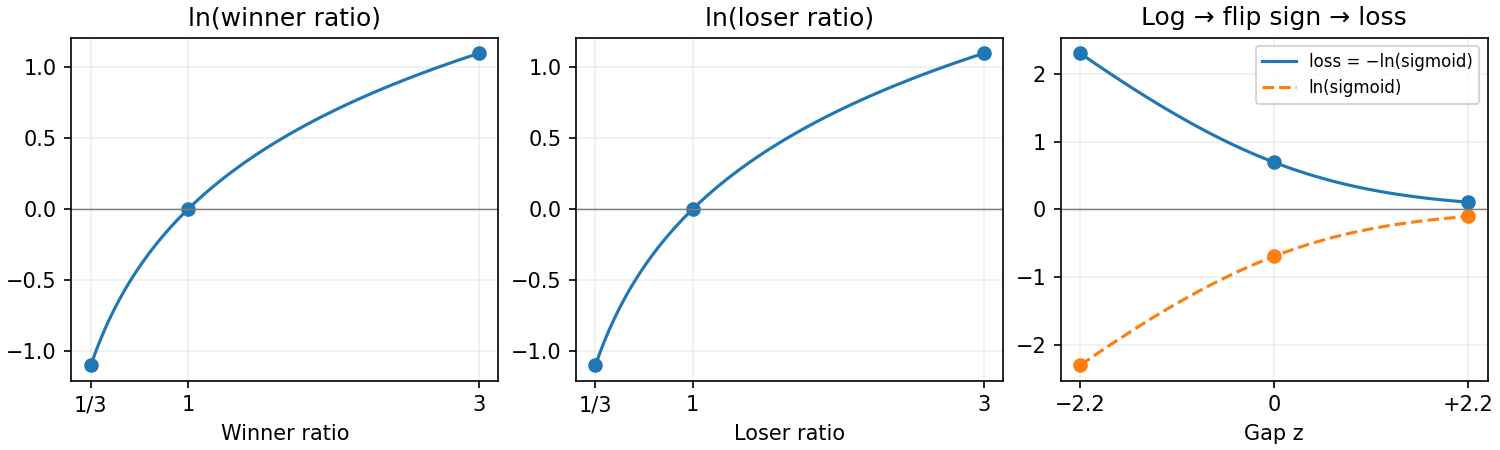

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Same three examples as the table; β = 1.
ratios = np.array([1/3, 1, 3])
winner = np.log(ratios)
loser = np.log(1 / ratios)
z = winner - loser
log_sigmoid = np.log(1 / (1 + np.exp(-z)))
loss = -log_sigmoid

ratio_curve = np.linspace(1/3, 3, 100)
gap_curve = np.linspace(z.min(), z.max(), 100)
log_sigmoid_curve = np.log(1 / (1 + np.exp(-gap_curve)))

fig, axes = plt.subplots(1, 3, figsize=(10, 3), layout='constrained')
for ax, name in zip(axes[:2], ['winner', 'loser']):
    ax.plot(ratio_curve, np.log(ratio_curve))
    ax.plot(ratios, np.log(ratios), 'o', color='tab:blue')
    ax.set(title=f'ln({name} ratio)', xlabel=f'{name.capitalize()} ratio',
           xticks=ratios, xticklabels=['1/3', '1', '3'])

axes[2].plot(gap_curve, -log_sigmoid_curve, label='loss = −ln(sigmoid)')
axes[2].plot(gap_curve, log_sigmoid_curve, '--', label='ln(sigmoid)')
axes[2].plot(z, loss, 'o', color='tab:blue')
axes[2].plot(z, log_sigmoid, 'o', color='tab:orange')
axes[2].set(title='Log → flip sign → loss', xlabel='Gap z',
            xticks=z, xticklabels=['−2.2', '0', '+2.2'])
axes[2].legend(fontsize=8)
for ax in axes:
    ax.axhline(0, color='gray', linewidth=0.7)
    ax.grid(alpha=0.2)
plt.show()
